# 🧪 06 - Visualization Lab: The Penguin Report, in Pictures

In the Module 07 lab you described the Palmer Penguins with **numbers**: a data dictionary, summary tables, outliers within species, and a Simpson's paradox in the bill measurements. Now the research team wants a **visual report**: a small set of figures that tells the same story to someone who'll never read a table.

You'll build it with everything from notebooks 01–05, check each figure against your Module 07 numbers, and save a finished figure set.

## ✅ Learning Goals
- Turn a numeric finding into the chart that shows it best
- Use one consistent, colorblind-safe palette and category order across a whole report
- Build single charts, small multiples, and a multi-panel summary figure
- Write titles that state findings, and check every chart against the numbers
- Export a complete, labeled figure set

```text
Load & clean (Module 07 lab) → Set report style → Distributions (03)
     → Group comparisons (03, 04) → Composition (02) → Relationships (04)
     → The paradox (04) → Summary figure (01) → Export
```

## 0. Setup
Everything this lab saves goes into **`06-OutputFiles`**. Upload that folder along with this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUT = Path('06-OutputFiles')
OUT.mkdir(exist_ok=True)

MEASUREMENTS = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Same cleaning as the Module 07 lab
penguins = pd.read_csv('penguins.csv').dropna(subset=MEASUREMENTS).copy()
penguins['sex'] = penguins['sex'].str.title()
print(penguins.shape)

(342, 7)


## 1. Set the Report Style Once
A report looks like **one** report when every chart uses the same theme, the same category order, and the same color for the same species (notebook 05). Define them once, at the top, and use them everywhere:

In [2]:
sns.set_theme(style='whitegrid', context='notebook')

SPECIES = ['Adelie', 'Chinstrap', 'Gentoo']
SPECIES_COLORS = dict(zip(SPECIES, sns.color_palette('colorblind', 3)))
SEX_COLORS = {'Female': '#999999', 'Male': '#333333'}

LABELS = {
    'bill_length_mm': 'Bill length (mm)',
    'bill_depth_mm': 'Bill depth (mm)',
    'flipper_length_mm': 'Flipper length (mm)',
    'body_mass_g': 'Body mass (g)',
}


def finish(ax, title, subtitle=None):
    """Apply the report's title style to an ax (notebook 05)."""
    ax.set_title(title, loc='left', fontweight='bold', pad=22 if subtitle else 6)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color='gray')
    ax.spines[['top', 'right']].set_visible(False)

`finish()` is notebook 01's "functions that draw on an `ax`" idea: every chart gets the same title style with one line.

## 2. Figure 1: Two Groups Hiding in One Distribution
**Module 07 finding:** body mass is roughly symmetric overall (skew ≈ 0.47), and Gentoos are about 1,350 g heavier than the other two species.

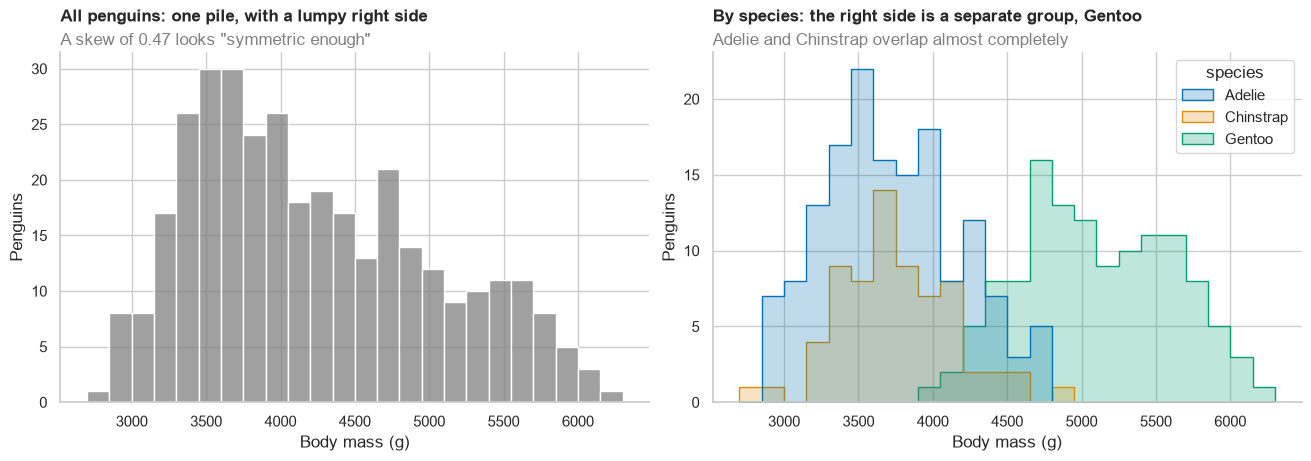

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, layout='constrained')

sns.histplot(data=penguins, x='body_mass_g', binwidth=150, color='gray', ax=axes[0])
finish(axes[0], 'All penguins: one pile, with a lumpy right side', 'A skew of 0.47 looks "symmetric enough"')

sns.histplot(data=penguins, x='body_mass_g', hue='species', hue_order=SPECIES,
             palette=SPECIES_COLORS, binwidth=150, element='step', ax=axes[1])
finish(axes[1], 'By species: the right side is a separate group, Gentoo', 'Adelie and Chinstrap overlap almost completely')

for ax in axes:
    ax.set(xlabel=LABELS['body_mass_g'], ylabel='Penguins')

fig.savefig(OUT / 'fig1_body_mass_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

✅ **Check against the numbers:** the Gentoo group should center near the Module 07 Gentoo mean (about 5,076 g), and the Adelie/Chinstrap humps near 3,700 g. Do they?

## 3. Figure 2: Species and Sex
**Module 07 finding:** within every species, males are heavier (by about 400–800 g).

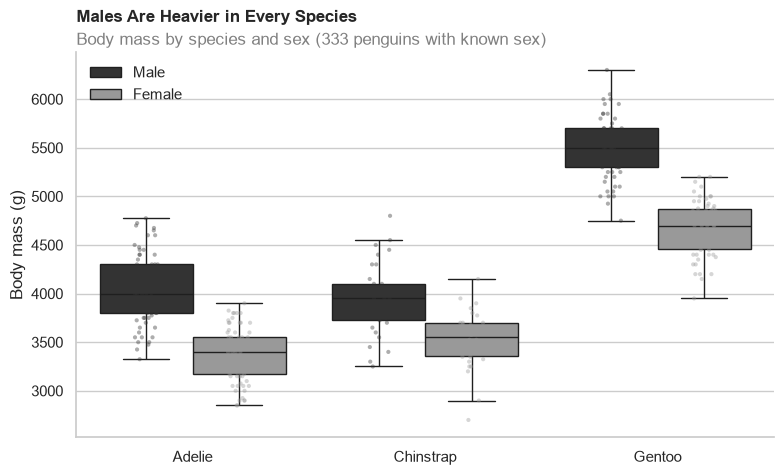

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex',
            order=SPECIES, palette=SEX_COLORS, showfliers=False, ax=ax)
sns.stripplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex',
              order=SPECIES, palette=SEX_COLORS, dodge=True, alpha=0.4, size=3,
              legend=False, ax=ax)
ax.set(xlabel='', ylabel=LABELS['body_mass_g'])
ax.legend(title='', frameon=False, loc='upper left')
finish(ax, 'Males Are Heavier in Every Species',
       f'Body mass by species and sex ({penguins["sex"].notna().sum()} penguins with known sex)')

fig.savefig(OUT / 'fig2_mass_by_species_sex.png', dpi=150, bbox_inches='tight')
plt.show()

The subtitle reports the sample size **after** dropping unknown sex, so the reader knows 9 penguins aren't in this chart (Module 07: always say what a summary is based on).

## 4. Figure 3: Where Each Species Lives
**Module 07 finding:** island and species are tangled together. Chinstraps were only measured on Dream, and Gentoos only on Biscoe.

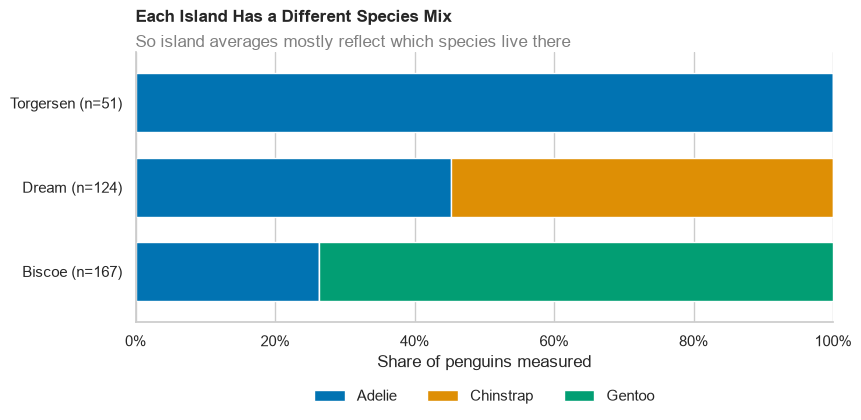

In [5]:
mix = pd.crosstab(penguins['island'], penguins['species'], normalize='index')[SPECIES]
counts = penguins['island'].value_counts()

fig, ax = plt.subplots(figsize=(9, 3.5))
mix.plot.barh(stacked=True, color=[SPECIES_COLORS[s] for s in SPECIES], width=0.7, ax=ax)
ax.set_yticks(range(len(mix)), [f'{island} (n={counts[island]})' for island in mix.index])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set(xlabel='Share of penguins measured', ylabel='')
ax.legend(title='', frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
finish(ax, 'Each Island Has a Different Species Mix',
       'So island averages mostly reflect which species live there')

fig.savefig(OUT / 'fig3_species_by_island.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Figure 4: How the Measurements Relate
**Module 07 finding:** flipper length and body mass are very strongly correlated (r ≈ 0.87).

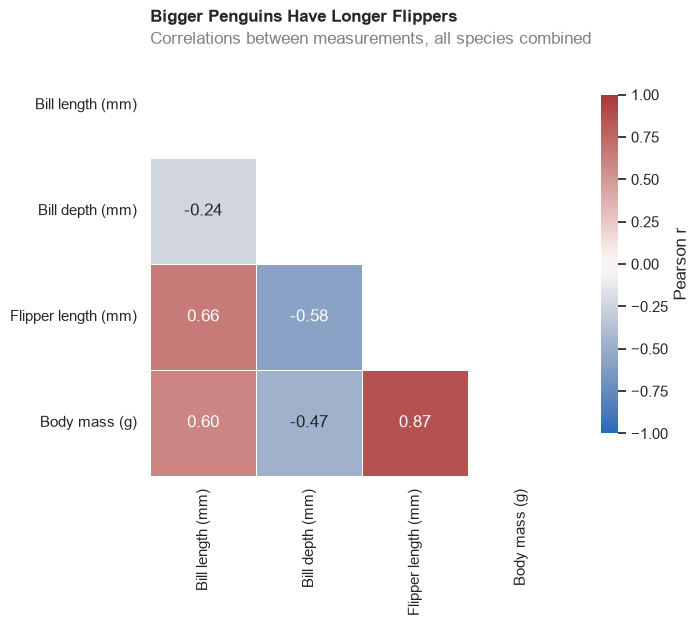

In [6]:
corr = penguins[MEASUREMENTS].rename(columns=LABELS).corr()
mask = np.triu(np.ones(corr.shape, dtype=bool))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={'label': 'Pearson r', 'shrink': 0.8}, ax=ax)
finish(ax, 'Bigger Penguins Have Longer Flippers', 'Correlations between measurements, all species combined')
ax.spines[['left', 'bottom']].set_visible(False)
ax.grid(False)        # the whitegrid theme would draw lines through the masked cells

fig.savefig(OUT / 'fig4_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Notice the subtitle: **all species combined.** You know from Module 07 that one of these numbers changes sign within species. That's the next figure, and it's yours to build.

---
## 🛠️ Your Figures
Sections 2–5 were worked examples. Sections 6 and 7 are yours. Use `SPECIES_COLORS`, `SPECIES`, `LABELS`, and `finish()` so they match the rest of the report.

## 6. Figure 5: The Paradox
Build a two-panel figure (`sharex=True, sharey=True`) of bill length vs. bill depth:
- **Left:** all penguins in gray, with one `regplot` trend line and the overall r in the subtitle.
- **Right:** colored by species, with one `regplot` line per species and each species' r in the legend.
- Titles that **state** the finding (for example, "Combined, Longer Bills Look Shallower" / "Within Every Species, Longer Bills Are Deeper").
- Save as `OUT / 'fig5_bill_paradox.png'`.

(Notebook 04 section 3 is your model, but use this report's style.)

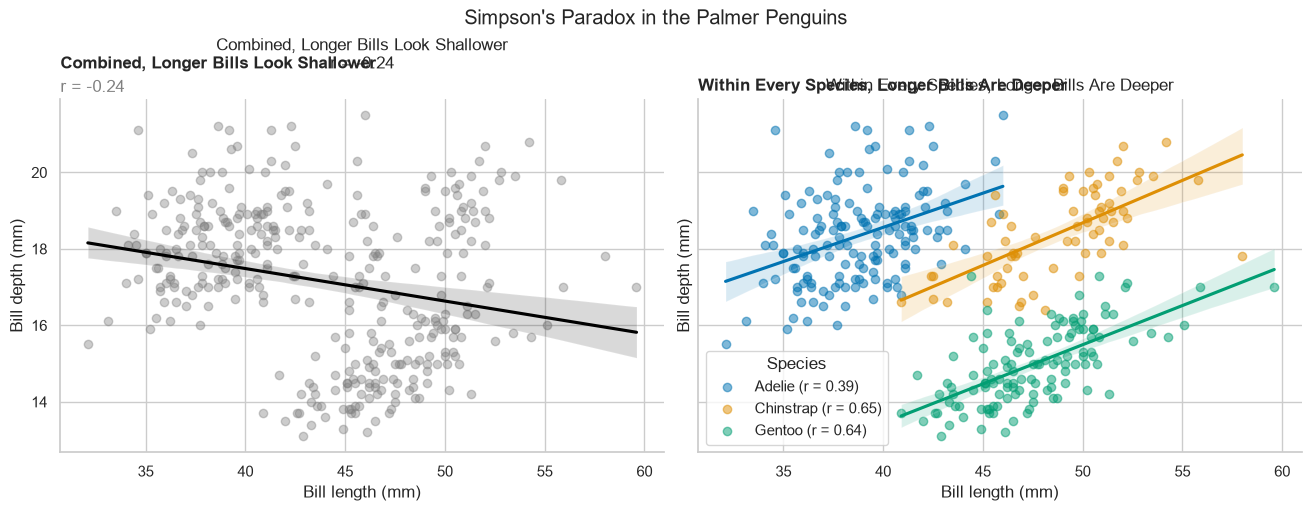

In [17]:
# Your Figure 5 here
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharex=True,
    sharey=True,
    layout='constrained'
)

# ------------------------------------------------------------------
# Left panel: all penguins together
# ------------------------------------------------------------------
r_all = penguins['bill_length_mm'].corr(penguins['bill_depth_mm'])

sns.regplot(
    data=penguins,
    x='bill_length_mm',
    y='bill_depth_mm',
    ax=axes[0],
    scatter_kws={'alpha': 0.4, 'color': 'gray'},
    line_kws={'color': 'black'}
)

axes[0].set_title(
    f'Combined, Longer Bills Look Shallower\nr = {r_all:.2f}'
)

# ------------------------------------------------------------------
# Right panel: one trend per species
# ------------------------------------------------------------------
for species in SPECIES:
    group = penguins[penguins['species'] == species]

    r = group['bill_length_mm'].corr(group['bill_depth_mm'])

    sns.regplot(
        data=group,
        x='bill_length_mm',
        y='bill_depth_mm',
        ax=axes[1],
        color=SPECIES_COLORS[species],
        scatter_kws={'alpha': 0.5},
        label=f'{species} (r = {r:.2f})'
    )

axes[1].set_title(
    'Within Every Species, Longer Bills Are Deeper'
)
axes[1].legend(title='Species')

# ------------------------------------------------------------------
# Common formatting
# ------------------------------------------------------------------
for ax in axes:
    ax.set(
        xlabel=LABELS['bill_length_mm'],
        ylabel=LABELS['bill_depth_mm']
    )

finish(
    axes[0],
    "Combined, Longer Bills Look Shallower",
    f"r = {r_all:.2f}"
)

finish(
    axes[1],
    "Within Every Species, Longer Bills Are Deeper"
)
fig.suptitle("Simpson's Paradox in the Palmer Penguins")
fig.savefig(OUT / 'fig5_bill_paradox.png', dpi=150)
plt.show()

## 7. Figure 6: The One-Page Summary
Build a single summary figure with `plt.subplot_mosaic()` (notebook 01 Challenge). The skeleton below creates the layout. Fill in each panel:
- `'dist'`: body mass by species (KDE or step histogram)
- `'paradox'`: the species-colored bill scatter from Figure 5
- `'flipper'`: flipper length vs. body mass, colored by species
- `'sex'`: mean body mass by species and sex (`barplot` or `pointplot`)

Give the figure a `suptitle` with the single most important finding, and save it as `OUT / 'fig6_summary.png'`.

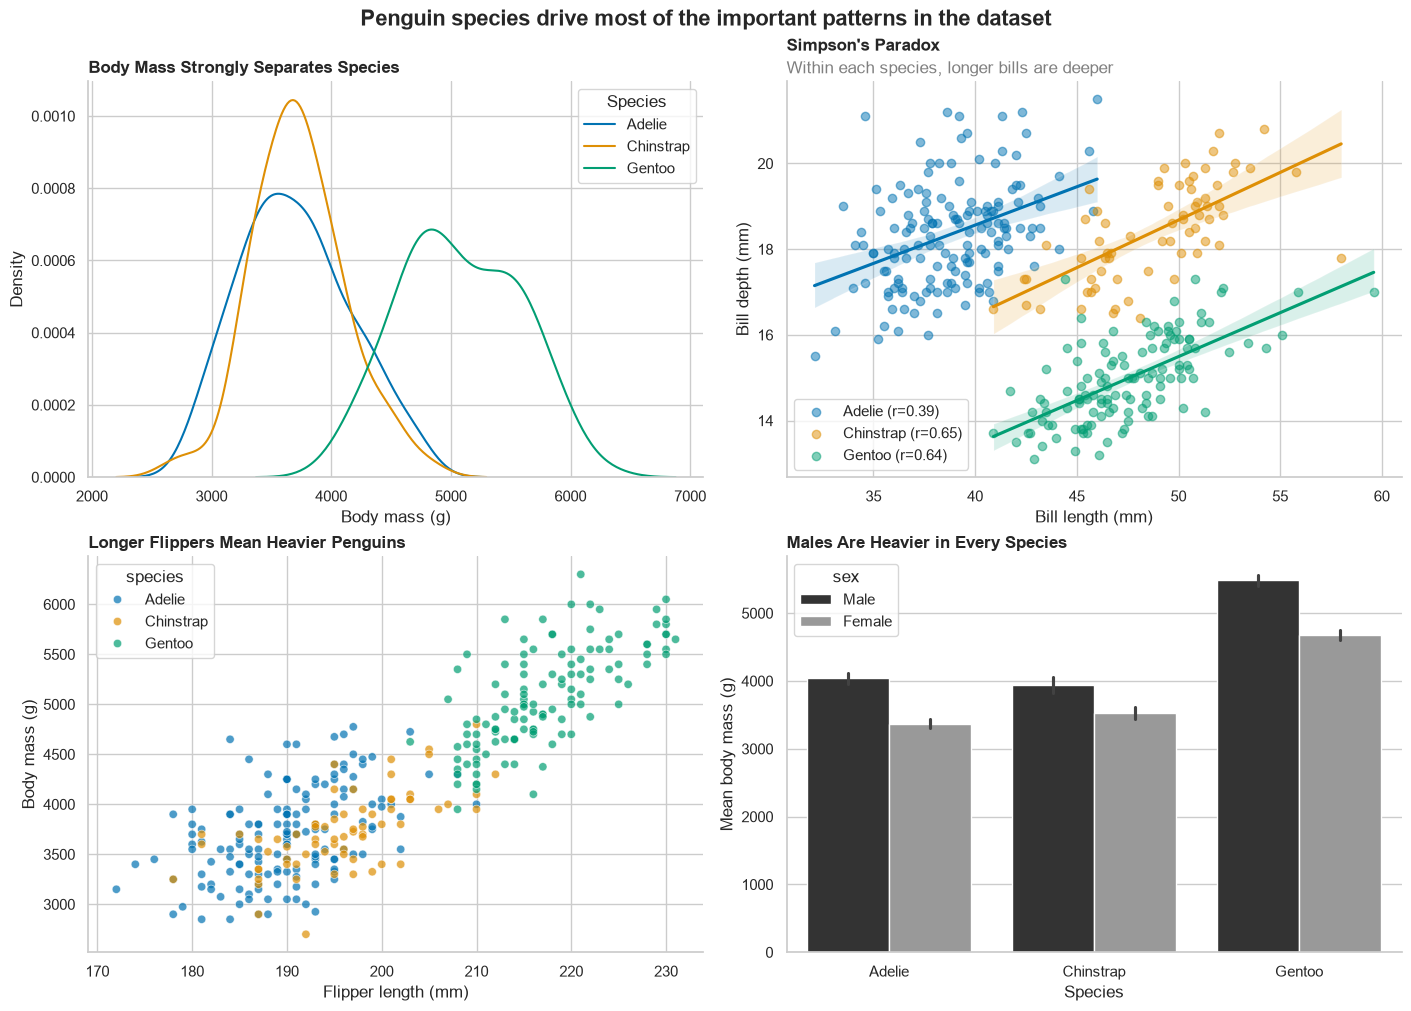

In [12]:
fig, axd = plt.subplot_mosaic(
    [['dist', 'paradox'],
     ['flipper', 'sex']],
    figsize=(14, 10), layout='constrained',
)

# TODO: draw on axd['dist'], axd['paradox'], axd['flipper'], and axd['sex']
# TODO: fig.suptitle(...)
# TODO: fig.savefig(OUT / 'fig6_summary.png', dpi=150, bbox_inches='tight')


# --------------------------------------------------
# dist: body mass distribution by species
# --------------------------------------------------
for species in SPECIES:
    sns.kdeplot(
        data=penguins[penguins['species'] == species],
        x='body_mass_g',
        ax=axd['dist'],
        color=SPECIES_COLORS[species],
        label=species,
    )

finish(
    axd['dist'],
    'Body Mass Strongly Separates Species'
)

axd['dist'].set(
    xlabel=LABELS['body_mass_g'],
    ylabel='Density'
)
axd['dist'].legend(title='Species')

# --------------------------------------------------
# paradox: species-colored bill scatter
# --------------------------------------------------
for species in SPECIES:
    group = penguins[penguins['species'] == species]

    r = group['bill_length_mm'].corr(group['bill_depth_mm'])

    sns.regplot(
        data=group,
        x='bill_length_mm',
        y='bill_depth_mm',
        ax=axd['paradox'],
        color=SPECIES_COLORS[species],
        scatter_kws={'alpha': 0.5},
        label=f'{species} (r={r:.2f})',
    )

finish(
    axd['paradox'],
    "Simpson's Paradox",
    'Within each species, longer bills are deeper'
)

axd['paradox'].set(
    xlabel=LABELS['bill_length_mm'],
    ylabel=LABELS['bill_depth_mm']
)
axd['paradox'].legend()

# --------------------------------------------------
# flipper: flipper length vs body mass
# --------------------------------------------------
sns.scatterplot(
    data=penguins,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='species',
    palette=SPECIES_COLORS,
    alpha=0.7,
    ax=axd['flipper']
)

finish(
    axd['flipper'],
    'Longer Flippers Mean Heavier Penguins'
)

axd['flipper'].set(
    xlabel=LABELS['flipper_length_mm'],
    ylabel=LABELS['body_mass_g']
)

# --------------------------------------------------
# sex: mean body mass by species and sex
# --------------------------------------------------
sns.barplot(
    data=penguins,
    x='species',
    y='body_mass_g',
    hue='sex',
    palette=SEX_COLORS,
    estimator=np.mean,
    ax=axd['sex']
)

finish(
    axd['sex'],
    'Males Are Heavier in Every Species'
)

axd['sex'].set(
    xlabel='Species',
    ylabel='Mean body mass (g)'
)

# --------------------------------------------------
# Figure title and save
# --------------------------------------------------
fig.suptitle(
    'Penguin species drive most of the important patterns in the dataset',
    fontsize=16,
    fontweight='bold'
)

fig.savefig(
    OUT / 'fig6_summary.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

## ❓ Lab Questions
Answer each in the Markdown cell below:
1. Figure 1: why did a skew of 0.47 (Module 07) fail to warn you that two groups were mixed together? What kind of chart reveals it, and what kind of statistic can't?
2. Figure 2: why does the chart use `showfliers=False` on the box plot? What would go wrong without it?
3. Figure 3: why is a 100% stacked bar a better choice here than a grouped count bar chart? What did adding `n=` to the labels fix?
4. Figure 5: explain Simpson's paradox from your chart alone, as if to someone who has never seen the numbers.
5. Which was easier to **find** the paradox with: the Module 07 tables or the Module 08 chart? Which is better as **evidence**? Why might you want both?
6. Pick one figure and go through the notebook 05 checklist. Which item did you have to fix last?

#### 1. Figure 1: why did a skew of 0.47 (Module 07) fail to warn you that two groups were mixed together? What kind of chart reveals it, and what kind of statistic can't?


A skewness of 0.47 failed to warn us because skewness is a single-number summary of the entire distribution. It measures asymmetry, but it does not tell us whether the data come from one group or several different groups. When the species were combined, the overall distribution of body mass looked only moderately right-skewed, so the skewness statistic did not signal that there were actually distinct Adelie, Chinstrap, and Gentoo subpopulations.

A distribution chart, such as a histogram, KDE plot, or density plot colored by species, reveals the problem because it shows the shape of the data. In Figure 1, the species-specific distributions and the separate peaks made it clear that multiple groups were mixed together.

A summary statistic like skewness cannot reveal this because it compresses the entire distribution into a single value. Two very different distributions can have similar skewness values. Likewise, statistics such as the mean, median, or standard deviation often hide multimodality and subgroup structure.

In short, a chart can reveal multiple peaks and clusters, while a single summary statistic cannot. That is why the histogram/KDE plot exposed the mixed species groups, but the skewness value of 0.47 did not.

#### 2. Figure 2: why does the chart use `showfliers=False` on the box plot? What would go wrong without it?
The chart uses showfliers=False because the individual observations are already displayed with the overlaid point plot. If the box plot also showed outliers, those observations would appear twice, making the figure cluttered and potentially misleading. Hiding the box-plot fliers keeps the chart cleaner while still showing all of the data points.

#### 3. Figure 3: why is a 100% stacked bar a better choice here than a grouped count bar chart? What did adding `n=` to the labels fix?

The 100% stacked bar chart helps compare the species diversity and composition within each island, while the n= labels show how many penguins contribute to each comparison. A 100% stacked bar chart is a better choice because the question is about composition rather than the total number of penguins on each island. By converting each bar to 100%, it becomes easy to compare the proportions of Adelie, Chinstrap, and Gentoo penguins within each island. A grouped count bar chart would emphasize differences in sample size and make it harder to compare the species mix across islands.

Adding n= to the island labels fixed the problem of hidden sample sizes. Two islands might have similar-looking percentages but very different numbers of penguins. Including labels such as Biscoe (n=168) and Dream (n=124) lets the reader see how much data each percentage is based on and judge the reliability of the comparison. It also makes clear that differences are not due simply to unequal numbers of observations.

#### 4. Figure 5: explain Simpson's paradox from your chart alone, as if to someone who has never seen the numbers
From the chart alone, Simpson's Paradox is visible because the overall trend line slopes downward, suggesting that penguins with longer bills tend to have shallower bills. However, when the data are separated by species, each species has an upward-sloping trend line, showing that within Adelie, Chinstrap, and Gentoo penguins, longer bills actually tend to be deeper. The apparent negative relationship in the combined data occurs because the species form distinct clusters with different typical bill sizes. As a result, the overall pattern is the opposite of the pattern seen within every species.

#### 5. Which was easier to **find** the paradox with: the Module 07 tables or the Module 08 chart? Which is better as **evidence**? Why might you want both?
So the best approach is to use both:

Tables help discover and verify the numerical pattern.
Charts help explain and communicate the pattern visually.
Together they provide both quantitative evidence (the correlations) and visual evidence (the species clusters and trend lines).

In this case, the table tells you that Simpson's Paradox is happening, while the chart shows you why it is happening.

*Your answers here.*

#### 6. Pick one figure and go through the notebook 05 checklist. Which item did you have to fix last?
Figure Chosen: Figure 5, "Simpson's Paradox in the Palmer Penguins"

Question: ✅
 The figure answers: How does the relationship between bill length and bill depth change when species are combined versus examined separately?

Type: ✅
 A scatter plot with regression lines is appropriate because both variables (bill_length_mm and bill_depth_mm) are quantitative and we want to examine correlation.

Title: ✅
 The panel titles state the finding ("Combined, Longer Bills Look Shallower" and "Within Every Species, Longer Bills Are Deeper") rather than merely describing the variables.

Labels: ✅
 Both axes are labeled with units (mm), and the legend identifies species. The sample consists of Palmer Penguins.

Scale: ✅
 Both panels share the same x- and y-scales (sharex=True, sharey=True), allowing fair comparison of the patterns.

Order: ✅
 Species appear in a consistent order (Adelie, Chinstrap, Gentoo) and use the same colors throughout the report.

Color: ✅
 Colors encode species membership only, use a colorblind-safe palette, and remain consistent with earlier figures.

Clutter: ✅
 The top and right spines were removed using finish(), and only essential legend and trend lines were retained.

Honesty: ✅
 All observations are shown, rather than summarized into averages that could hide the underlying pattern. The figure explicitly reveals the Simpson's Paradox that would be missed in the combined view.

Which item did I have to fix last?

Title. Initially, my titles only described the chart (for example, "Bill Length vs. Bill Depth"). I revised them to communicate the actual conclusion, making it easier for a reader to understand the key finding without having to interpret the chart first.

## 🏋️ Practice

### Practice 1 — Flipper Length by Species (easy)
Make a violin plot of `flipper_length_mm` by species, with `order=SPECIES` and `palette=SPECIES_COLORS`. Write a title that states the finding, using `finish()`.

C:\Users\Nazmun\AppData\Local\Temp\ipykernel_28644\3557246361.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


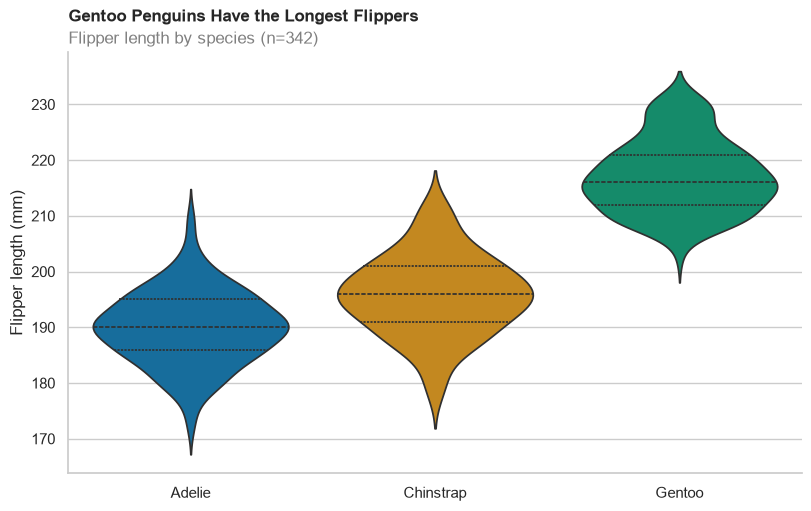

In [19]:
# Your code here
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')

sns.violinplot(
    data=penguins,
    x='species',
    y='flipper_length_mm',
    order=SPECIES,
    palette=SPECIES_COLORS,
    inner='quart',
    ax=ax
)

ax.set(
    xlabel='',
    ylabel='Flipper length (mm)'
)

finish(
    ax,
    'Gentoo Penguins Have the Longest Flippers',
    f'Flipper length by species (n={penguins["flipper_length_mm"].notna().sum()})'
)

fig.savefig(OUT / 'flipper_violin_species.png', dpi=150, bbox_inches='tight')
plt.show()


### Practice 2 — Small Multiples (medium)
Use `sns.displot()` to draw `bill_depth_mm` with `col='species'` and `hue='sex'`, using the report's colors and order. Save it as `OUT / 'practice_bill_depth_grid.png'`.

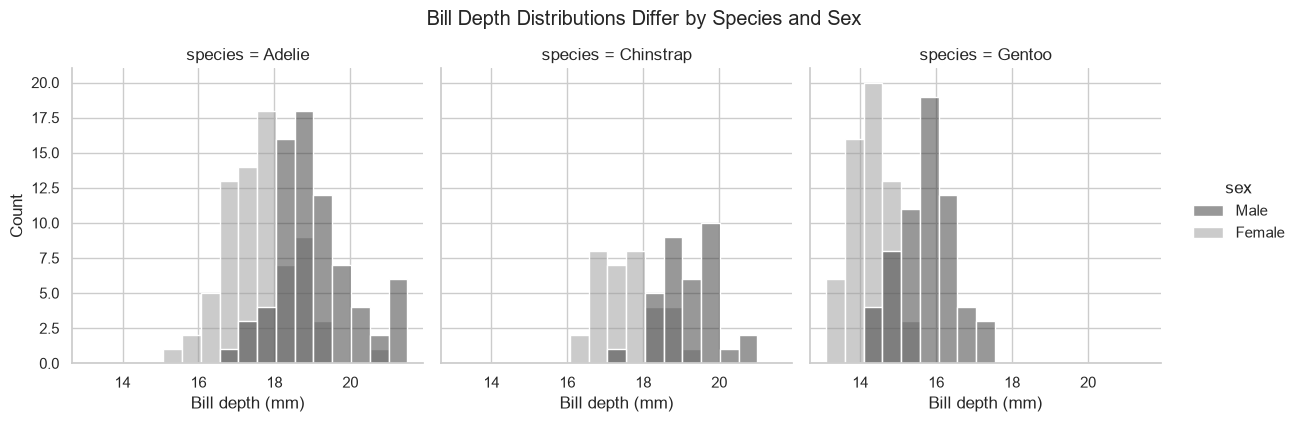

In [26]:
# Your code here
import seaborn as sns
g = sns.displot(
    data=penguins,
    x='bill_depth_mm',
    col='species',
    hue='sex',
    col_order=SPECIES,
    #hue_order=SEX,        # e.g. ['Female', 'Male']
    palette=SEX_COLORS,   # colors for sex
    binwidth=0.5,
    height=4,
    aspect=1
)

g.set_axis_labels('Bill depth (mm)', 'Count')

g.figure.suptitle(
    'Bill Depth Distributions Differ by Species and Sex',
    y=1.05
)

g.savefig(OUT / 'practice_bill_depth_grid.png', dpi=150, bbox_inches='tight')
plt.show()

### Practice 3 — A Fair Island Comparison (harder)
Module 07's lab Practice 2 compared Adelie body mass across islands (the only species on all three). Make the chart version: a box + strip plot of Adelie `body_mass_g` by island, with sample sizes in the tick labels. Does the chart agree with your numbers?

In [ ]:
mix = pd.crosstab(penguins['island'], penguins['species'], normalize='index')[SPECIES]
counts = penguins['island'].value_counts()

fig, ax = plt.subplots(figsize=(9, 3.5))
mix.plot.barh(stacked=True, color=[SPECIES_COLORS[s] for s in SPECIES], width=0.7, ax=ax)
ax.set_yticks(range(len(mix)), [f'{island} (n={counts[island]})' for island in mix.index])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set(xlabel='Share of penguins measured', ylabel='')
ax.legend(title='', frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
finish(ax, 'Each Island Has a Different Species Mix',
       'So island averages mostly reflect which species live there')

fig.savefig(OUT / 'fig3_species_by_island.png', dpi=150, bbox_inches='tight')
plt.show()

C:\Users\Nazmun\AppData\Local\Temp\ipykernel_28644\236103863.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


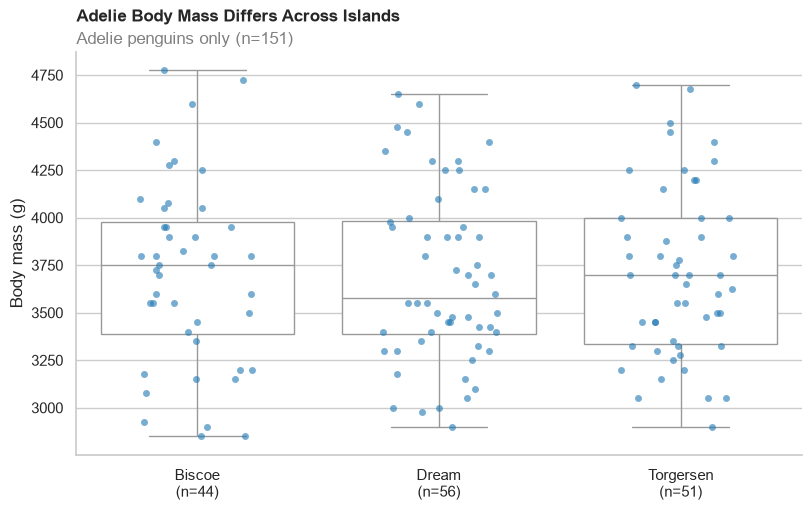

In [31]:
adelie = penguins[penguins['species'] == 'Adelie'].copy()

islands = sorted(adelie['island'].dropna().unique())

counts = adelie['island'].value_counts().reindex(islands)

labels = [f'{island}\n(n={counts[island]})' for island in islands]

fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')

sns.boxplot(
    data=adelie,
    x='island',
    y='body_mass_g',
    order=islands,
    color='white',
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=adelie,
    x='island',
    y='body_mass_g',
    order=islands,
    color='tab:blue',
    alpha=0.6,
    jitter=0.25,
    ax=ax
)

ax.set(
    xticklabels=labels,
    xlabel='',
    ylabel='Body mass (g)'
)

finish(
    ax,
    'Adelie Body Mass Differs Across Islands',
    f'Adelie penguins only (n={len(adelie)})'
)

fig.savefig(OUT / 'adelie_mass_by_island.png', dpi=150, bbox_inches='tight')
plt.show()

Yes. The chart agrees with the summary statistics from Module 07. Adelie penguins on Biscoe tend to have the highest body mass, while Dream and Torgersen are somewhat lighter. The box and strip plots also show the amount of overlap and variability within each island, which was not visible from the summary numbers alone.

## ✏️ Challenge Task
Make a **pair plot** of the four measurements with `hue='species'`, `corner=True`, and the report palette. Find the pair of measurements that separates all three species most cleanly, then make a **polished** single scatter plot of just that pair, with a finding title and direct species labels instead of a legend (hint: `ax.text()` at each species' mean position). Save it as `OUT / 'fig7_best_separator.png'`.

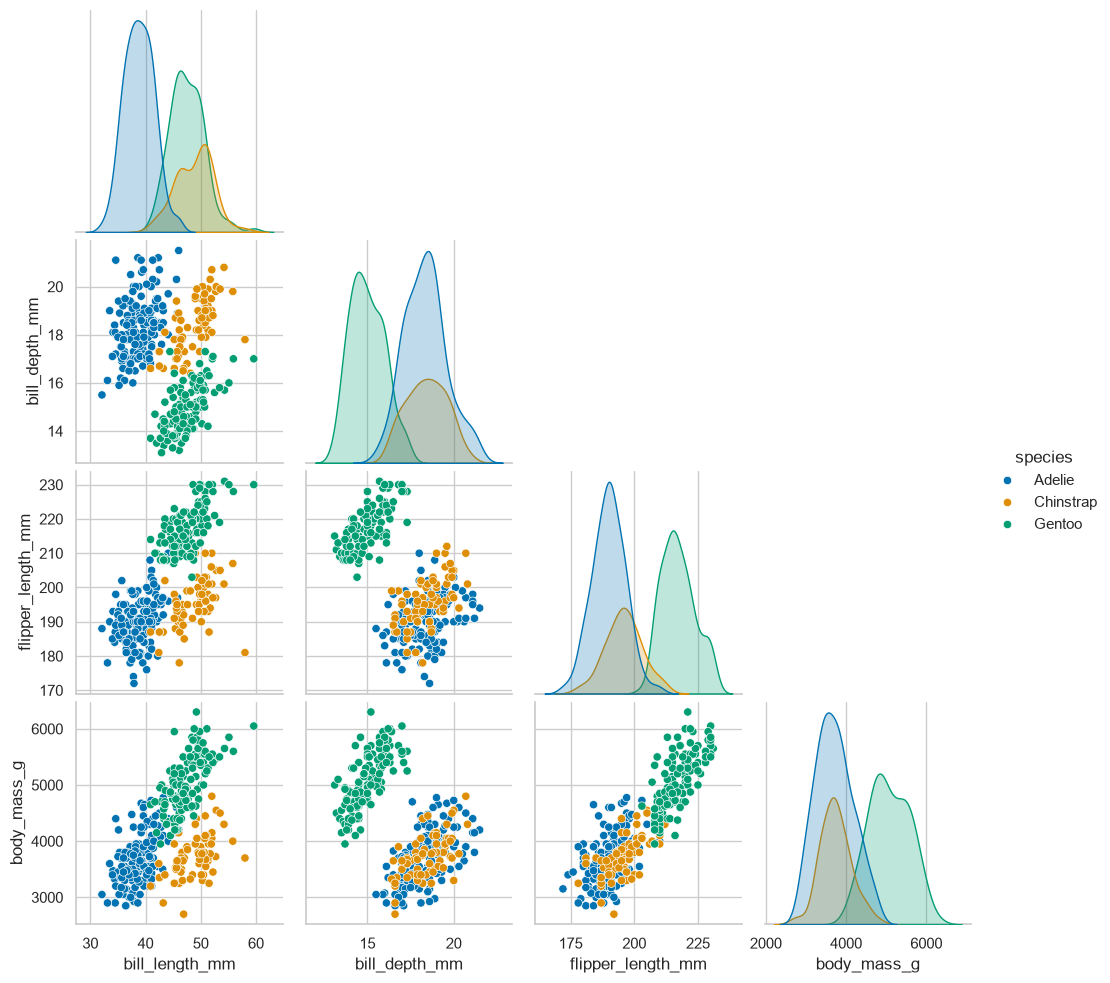

In [32]:
# Your code here
measures = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

sns.pairplot(
    data=penguins,
    vars=measures,
    hue='species',
    palette=SPECIES_COLORS,
    corner=True
)

plt.show()

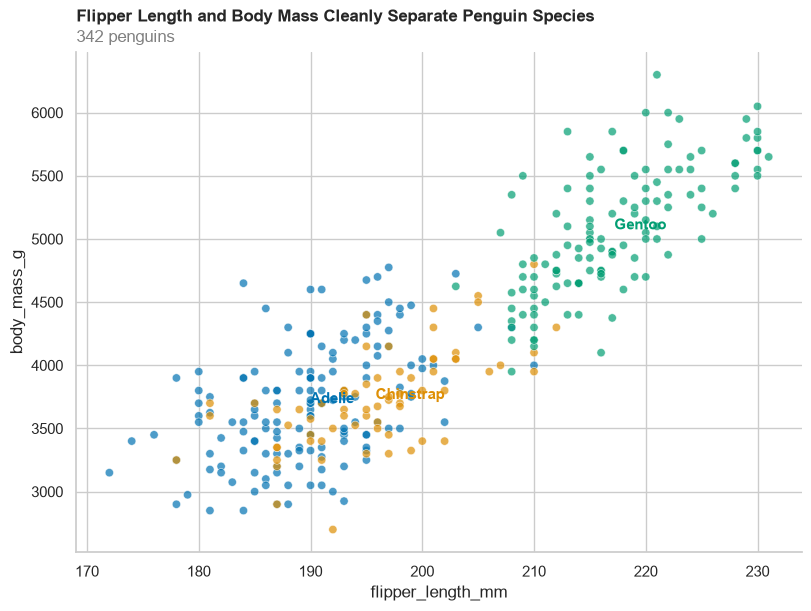

In [33]:
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')

sns.scatterplot(
    data=penguins,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='species',
    palette=SPECIES_COLORS,
    alpha=0.7,
    legend=False,
    ax=ax
)

# Direct labels at species means
means = (
    penguins
    .groupby('species')[['flipper_length_mm', 'body_mass_g']]
    .mean()
)

for species in SPECIES:
    x = means.loc[species, 'flipper_length_mm']
    y = means.loc[species, 'body_mass_g']

    ax.text(
        x,
        y,
        species,
        color=SPECIES_COLORS[species],
        weight='bold',
        fontsize=11
    )

finish(
    ax,
    'Flipper Length and Body Mass Cleanly Separate Penguin Species',
    f'{penguins.shape[0]} penguins'
)

fig.savefig(
    OUT / 'fig7_best_separator.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

Flipper length and body mass provide the clearest separation among the three penguin species. Gentoo penguins cluster at high body mass and long flipper lengths, Adelie penguins cluster at lower values, and Chinstrap penguins fall between them with relatively little overlap.

## 🔥 Challenge (Optional) — A Visual Report on New Data
Pick `titanic.csv` or `pokemon.csv` (copy it into this folder, or use the path `../07-Describing_Data/`). Ask **three** questions, and answer each with one finished chart (finding title, consistent palette, honest scales), saved to `OUT` with a `challenge_` prefix. Write one sentence per chart summarizing the finding.

In [ ]:
# Your code here

*Your three findings here.*

## 📦 Check Your Output Files
Run this last. Everything you saved should be inside `06-OutputFiles`. Upload that folder along with this notebook.

In [34]:
for path in sorted(OUT.rglob('*')):
    print(path)

06-OutputFiles\adelie_mass_by_island.png
06-OutputFiles\adelie_mass_by_island_1.png
06-OutputFiles\fig1_body_mass_distribution.png
06-OutputFiles\fig2_mass_by_species_sex.png
06-OutputFiles\fig3_species_by_island.png
06-OutputFiles\fig4_correlation_heatmap.png
06-OutputFiles\fig5_bill_paradox.png
06-OutputFiles\fig6_summary.png
06-OutputFiles\fig7_best_separator.png
06-OutputFiles\flipper_violin_SPECIES.png
06-OutputFiles\practice_bill_depth_grid.png


---
### 📝 Summary
This lab turned a numeric report into a visual one:
- **One style for the whole report**: a theme, a category order, a palette dictionary, and a `finish()` helper
- **Distributions** revealed a second group that the skew statistic hid
- **Box + strip** showed both the summary and every penguin
- **Composition** made the island/species confounder visible, with sample sizes
- **Heatmap + paradox figure**: the combined correlation, and why it misleads
- **Every chart was checked against the Module 07 numbers**: charts and statistics work best together

🎓 That's Module 08, and the end of the course's core material. For the **final project**, you'll run this whole cycle (load, clean, describe, visualize, explain) on a dataset of your own.